# Global navigation
Choose an image below and run the cells from top to bottom. Settings are in `global_navigation/config.py`.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import computer_vision as vision
import global_navigation as nav

image_path = Path("img/playground/1_play.jpg")

config = nav.NavigationConfig()
print(f"Clearance: {100 * config.clearance_m:.1f} cm")


Clearance: 8.1 cm


### 1. Computer vision

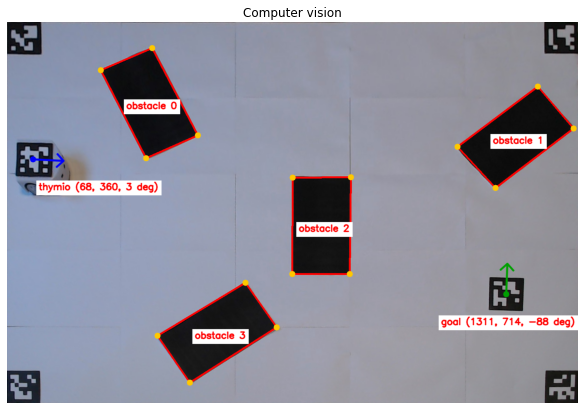

In [6]:
image = vision.load_image(image_path)
frame = vision.analyse_frame(image)
vision.show(vision.draw_frame(frame), "Computer vision")
plt.show()


### 2. Plan and show the path

Start is outside the map or in an obstacle/clearance zone


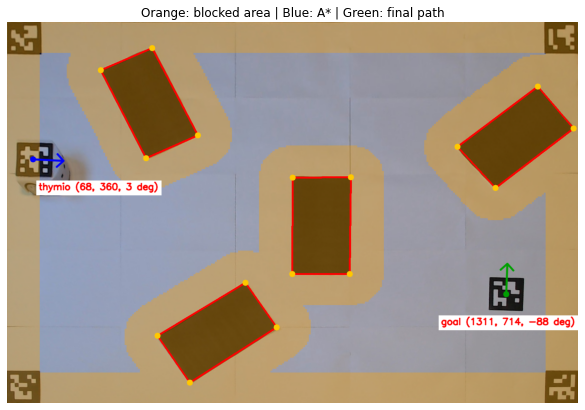

In [7]:
plan = None
try:
    plan = nav.plan_path(frame, config)
    print(f"Path length: {nav.path_length(plan.waypoints):.2f} m")
except ValueError as error:
    print(error)

grid = plan.grid if plan is not None else nav.build_grid(frame, config)
vision.show(nav.draw_navigation(frame, plan, grid),
            "Orange: blocked area | Blue: A* | Green: final path")
plt.show()


### 3. Waypoints

In [8]:
if plan is not None:
    waypoints_m = plan.waypoints
    print("First five waypoints [x, y] in metres:")
    print(waypoints_m[:5])
